In [1]:

print("My ANN Binary Classification Project")
print("Google Colab is working!")


My ANN Binary Classification Project
Google Colab is working!


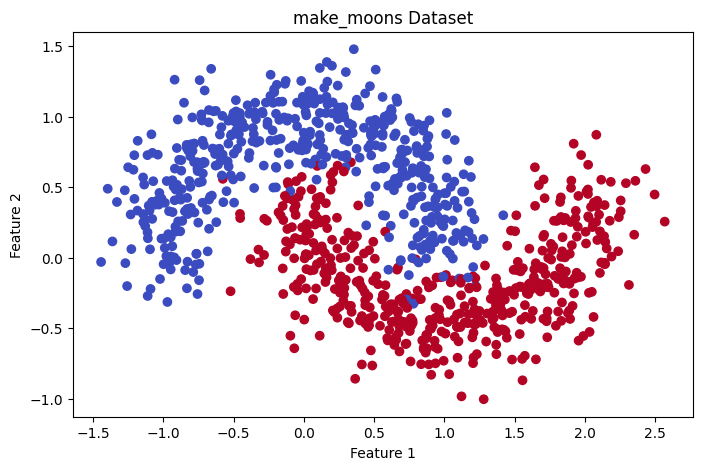

Dataset created successfully!
Number of data points: 1000


In [2]:

from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

# Create the dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

# Display the dataset
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm")

plt.title("make_moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Dataset created successfully!")
print("Number of data points:", len(X))


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scale the data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Display the results
print("Training data:", X_train.shape[0])
print("Testing data:", X_test.shape[0])
print("Data preprocessing completed!")


Training data: 800
Testing data: 200
Data preprocessing completed!


In [4]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Create the ANN model
model = keras.Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

# Configure the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465 (1.82 KB)

 Trainable params: 465 (1.82 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:

# Train the ANN model

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("ANN Model Training Completed!")


Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8313 - loss: 0.6276 - val_accuracy: 0.8938 - val_loss: 0.5778
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8203 - loss: 0.5691 - val_accuracy: 0.8875 - val_loss: 0.5065
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8219 - loss: 0.5089 - val_accuracy: 0.8875 - val_loss: 0.4337
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8266 - loss: 0.4515 - val_accuracy: 0.8875 - val_loss: 0.3666
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8375 - loss: 0.4025 - val_accuracy: 0.9000 - val_loss: 0.3130
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8406 - loss: 0.3670 - val_accuracy: 0.9000 - val_loss: 0.2746
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8484 - loss: 0.3419 - val_accuracy: 0.9062 - val_loss: 0.2530
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8547 - loss: 0.3268 - val_accuracy: 0.9125

In [6]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict the test data
y_prob = model.predict(X_test, verbose=0)

# Convert probabilities into classes: 0 or 1
y_pred = (y_prob >= 0.5).astype(int).ravel()

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("ANN MODEL EVALUATION RESULTS")
print("----------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


ANN MODEL EVALUATION RESULTS
----------------------------
Accuracy : 99.0 %
Precision: 0.9804
Recall   : 1.0
F1 Score : 0.9901

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       100
           1       0.98      1.00      0.99       100

    accuracy                           0.99       200
   macro avg       0.99      0.99      0.99       200
weighted avg       0.99      0.99      0.99       200



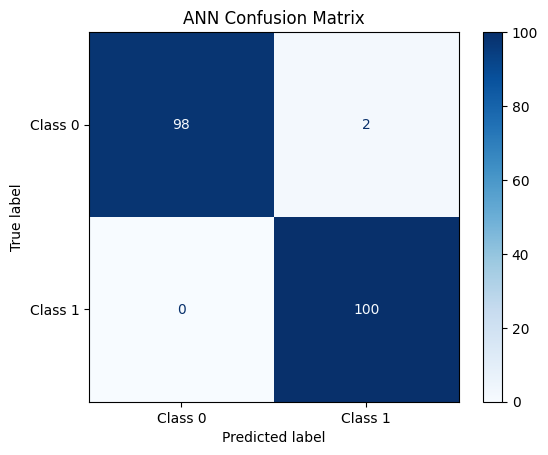

Confusion Matrix:
[[ 98   2]
 [  0 100]]


In [7]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

disp.plot(cmap="Blues")
plt.title("ANN Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)


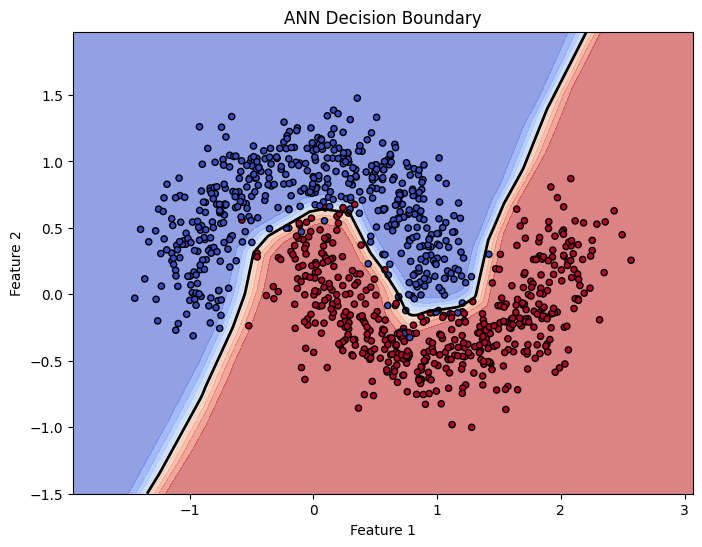

In [8]:

import numpy as np
import matplotlib.pyplot as plt

# Create a grid for plotting
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Scale the data and predict using ANN
grid_scaled = scaler.transform(grid)
Z = model.predict(grid_scaled, verbose=0).reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy, Z,
    levels=np.linspace(0, 1, 11),
    cmap="coolwarm",
    alpha=0.6
)

plt.contour(
    xx, yy, Z,
    levels=[0.5],
    colors="black",
    linewidths=2
)

plt.scatter(
    X[:, 0], X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolor="black",
    s=20
)

plt.title("ANN Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


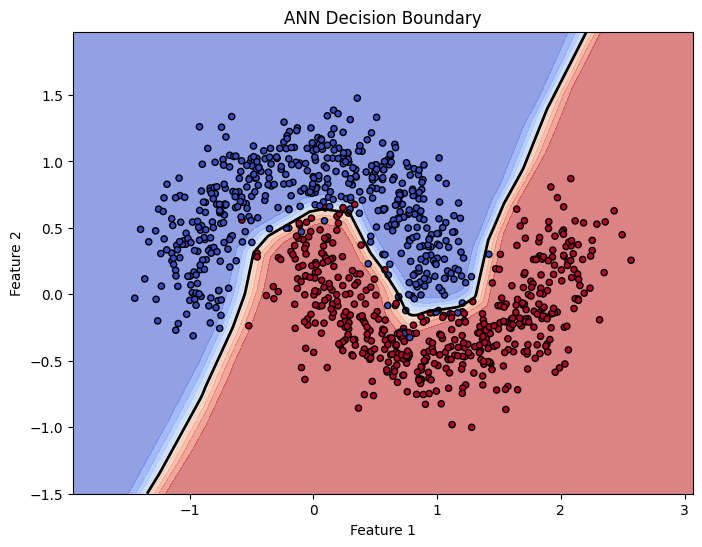

Decision Boundary plotted successfully!


In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Create a grid for the graph
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Scale the grid data
grid_scaled = scaler.transform(grid)

# Predict using the trained ANN model
Z = model.predict(grid_scaled, verbose=0).reshape(xx.shape)

# Plot the decision boundary
plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy, Z,
    levels=np.linspace(0, 1, 11),
    cmap="coolwarm",
    alpha=0.6
)

plt.contour(
    xx, yy, Z,
    levels=[0.5],
    colors="black",
    linewidths=2
)

plt.scatter(
    X[:, 0], X[:, 1],
    c=y,
    cmap="coolwarm",
    edgecolor="black",
    s=20
)

plt.title("ANN Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Decision Boundary plotted successfully!")


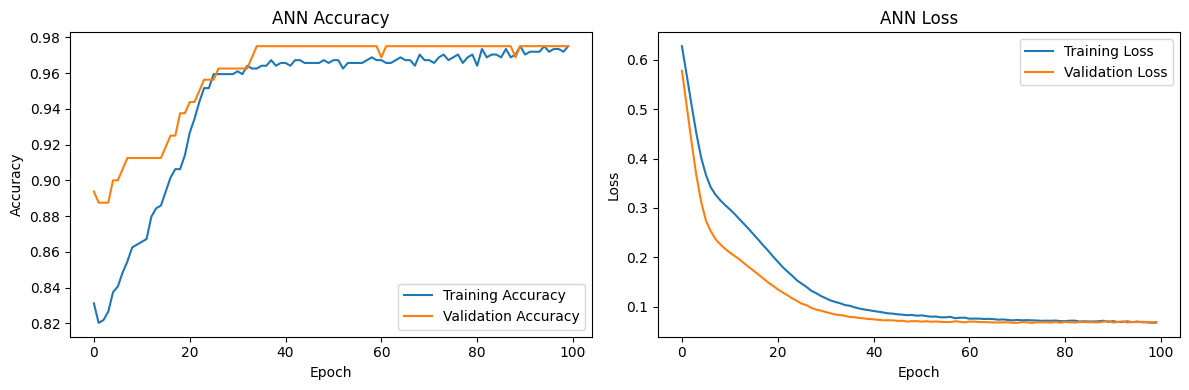

Training Accuracy and Loss Graphs created successfully!


In [10]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

print("Training Accuracy and Loss Graphs created successfully!")
